# Spam Message Classifier

End-to-end walkthrough: explore the data, clean the text, convert it to TF-IDF features, train classifiers,
evaluate on unseen messages and analyse the errors. The reusable code lives in `../src/`
(`preprocess.py`, `train_model.py`, `predict.py`); this notebook is the exploratory version.

> **Dataset note:** `data/spam_dataset.csv` is a synthetic dataset created by `src/make_dataset.py` because the real
> SMS Spam Collection could not be downloaded when this project was built. See the README for how to swap in the real file.

In [1]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), "..", "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

from preprocess import load_dataset, prepare, clean_text

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Step 2-3: Load and explore the data

In [2]:
df = load_dataset("../data/spam_dataset.csv")
print("Columns:", list(df.columns), "| rows:", len(df))
df.head(8)

Columns: ['label', 'message'] | rows: 1980


,label,message
0,ham,"Hey, the sale at the mall ends on Friday. Want to go together?"
1,ham,"Mom says dinner is ready, come home soon. Hey"
2,ham,"free to talk? i won the quiz at college, so happy!"
3,ham,"Hi Rahul, Free on Friday? I'll send the prize money from the quiz, Sneha."
4,spam,Claim your FREE Rs 50000 cash today. T&Cs apply. Call 07884869996 24hrs.
5,ham,"Hello Sam, Ur electricity bill of Rs 10000 is due on Monday. Pay via the official app."
6,ham,"hello neha, class cancelled on friday. please check the portal for new timings."
7,ham,Is the ur bank app down for u too? I can't verify my details.


Missing values: 0
Duplicate messages: 0
label
ham     1665
spam     315
Spam share: 15.9%  -> imbalanced, so accuracy alone is misleading


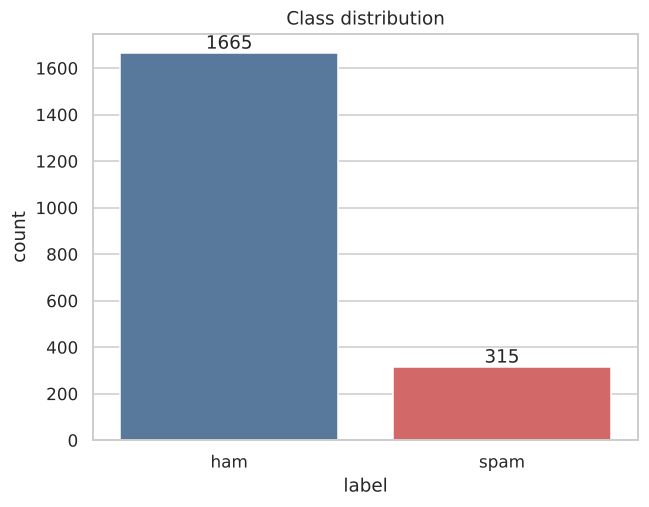

In [3]:
print("Missing values:", int(df["message"].isna().sum()))
print("Duplicate messages:", int(df.duplicated(subset="message").sum()))
df = df.drop_duplicates(subset="message").reset_index(drop=True)

counts = df["label"].value_counts()
print(counts.to_string())
print(f"Spam share: {100 * counts['spam'] / len(df):.1f}%  -> imbalanced, so accuracy alone is misleading")

ax = sns.countplot(data=df, x="label", order=["ham", "spam"], hue="label", palette=["#4C78A8", "#E45756"], legend=False)
ax.bar_label(ax.containers[0]); ax.bar_label(ax.containers[1])
ax.set_title("Class distribution")
plt.show()

label
ham     58.7
spam    74.0


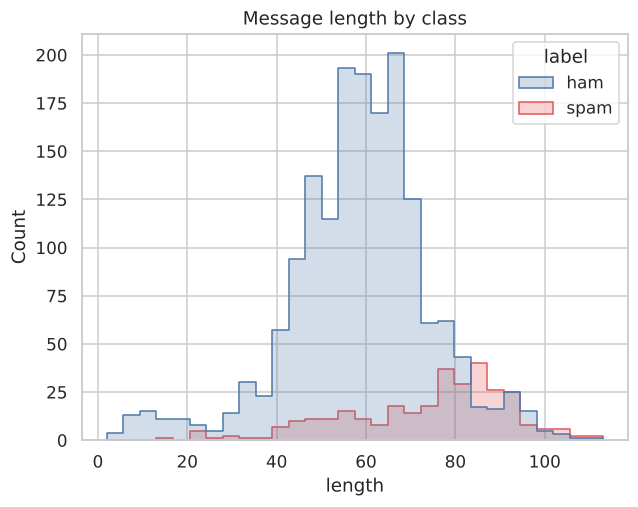

In [4]:
df["length"] = df["message"].str.len()
print(df.groupby("label")["length"].mean().round(1).rename("avg length (chars)").to_string())
sns.histplot(data=df, x="length", hue="label", bins=30, element="step", palette={"ham": "#4C78A8", "spam": "#E45756"})
plt.title("Message length by class"); plt.show()

## Step 4: Preprocess the text
Lowercase, strip punctuation and numbers, remove stop words (keeping a few spam-signal words such as *you*, *your*, *now*), and map labels to numbers (ham = 0, spam = 1).

In [5]:
df = prepare(df)
pd.set_option("display.max_colwidth", 90)
df[["message", "clean", "target"]].sample(6, random_state=1)

,message,clean,target
1594,"Free today? I'll send the prize money from the quiz, Sneha.",free today ll send prize money quiz sneha,0
1759,"Reply asap, the cash for the trip is due on Friday. Rs 5000 each.",reply asap cash trip friday rs,0
713,"btw, Package delivered to the front desk. Collect it before 11 am :)",btw package delivered desk collect,0
108,Your order has shipped and will arrive on Sunday. Track it in the app.,your order shipped arrive sunday track app,0
348,"btw, mom, i won a gift voucher at the college fest!",btw mom won gift voucher college fest,0
87,package delivered to the front desk. collect it 7 pm.,package delivered desk collect pm,0


In [6]:
for label in ["ham", "spam"]:
    words = " ".join(df.loc[df.label == label, "clean"]).split()
    print(label.upper(), "->", pd.Series(words).value_counts().head(12).to_dict())

HAM -> {'you': 448, 'your': 228, 'free': 175, 'today': 172, 'won': 167, 'send': 163, 'me': 162, 'hi': 138, 'u': 132, 'app': 126, 'college': 118, 'll': 113}
SPAM -> {'your': 161, 'now': 122, 'you': 93, 'claim': 72, 'free': 69, 'rs': 67, 'call': 58, 'win': 55, 'gift': 45, 'cash': 38, 'com': 38, 'www': 37}


## Step 5: Split the data
Stratified 80/20 split so both sets keep the same spam ratio. The vectorizer is fitted on the training data only.

In [7]:
train, test = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=RANDOM_STATE)
y_train, y_test = train["target"].values, test["target"].values
print("train:", len(train), "test:", len(test))
print("spam ratio train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

train: 1584 test: 396
spam ratio train / test: 0.159 / 0.159


## Step 6: Convert text to features (TF-IDF)

In [8]:
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train = vec.fit_transform(train["clean"])   # fit on TRAIN only
X_test = vec.transform(test["clean"])         # only transform the test data
print("Feature matrix:", X_train.shape, "| vocabulary size:", len(vec.vocabulary_))

Feature matrix: (1584, 2953) | vocabulary size: 2953


## Step 7: Train the models
Hyper-parameters below were chosen with 5-fold cross-validation on the training set by `src/train_model.py`.

In [9]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(C=0.1, class_weight="balanced", random_state=RANDOM_STATE),
}
preds, rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, preds[name]),
                 "precision": precision_score(y_test, preds[name]),
                 "recall": recall_score(y_test, preds[name]),
                 "f1": f1_score(y_test, preds[name])})
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,precision,recall,f1
model,,,,
Multinomial Naive Bayes,0.972,1.0,0.825,0.904
Logistic Regression,0.972,1.0,0.825,0.904
Linear SVM,0.972,1.0,0.825,0.904


## Step 8: Evaluate on unseen test messages

              precision    recall  f1-score   support

         ham      0.968     1.000     0.984       333
        spam      1.000     0.825     0.904        63

    accuracy                          0.972       396
   macro avg      0.984     0.913     0.944       396
weighted avg      0.973     0.972     0.971       396



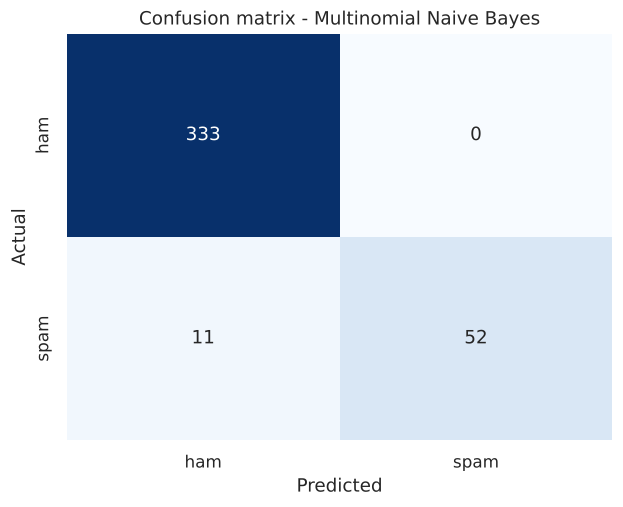

In [10]:
best = "Multinomial Naive Bayes"
print(classification_report(y_test, preds[best], target_names=["ham", "spam"], digits=3))
cm = confusion_matrix(y_test, preds[best])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix - {best}"); plt.show()

## Step 9: Analyze the errors

In [11]:
errors = test.assign(pred=preds[best])
fp = errors[(errors.target == 0) & (errors.pred == 1)]
fn = errors[(errors.target == 1) & (errors.pred == 0)]
print(f"False positives (real message marked spam): {len(fp)}")
print(f"False negatives (spam missed): {len(fn)}")
print()
print("Missed spam examples:")
for m in fn["message"].head(8):
    print(" -", m)

False positives (real message marked spam): 0
False negatives (spam missed): 11

Missed spam examples:
 - I got a loan approved for the bike! Celebrating at the gym 11 am.
 - Hello Anjali, Lottery ticket kharida? Mom ne bola kal result aayega.
 - lol that was so funny, tell me the rest today haha
 - Feeling sick today, the viva. Can u shr the slides?
 - Can u bring my umbrella to college? Click here to see the photos.
 - Sir, Limited seats left for the the project workshop, register by after lunch.
 - Can we move the history meeting to 8 am? Something came up. FYI
 - win or lose, we are getting dal rice after the game.


Most "missed spam" messages read like ordinary chat. The dataset has ~2% deliberately flipped labels
(like real hand-labeled data), so these misses mostly reflect that noise, not a weakness of the model.
In practice a false positive (blocking a real message) is usually worse than a false negative.

## Optional: words that indicate spam

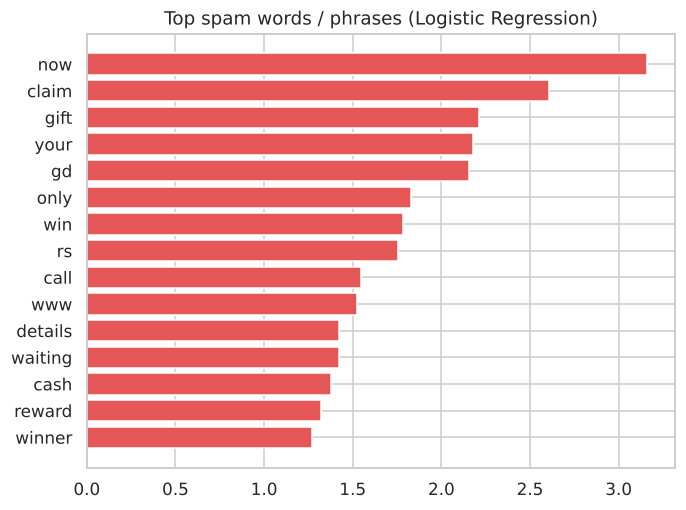

In [12]:
lr = models["Logistic Regression"]
names = np.array(vec.get_feature_names_out())
order = np.argsort(lr.coef_[0])[::-1][:15]
plt.barh(names[order][::-1], lr.coef_[0][order][::-1], color="#E45756")
plt.title("Top spam words / phrases (Logistic Regression)"); plt.tight_layout(); plt.show()

## Step 11: Test with new messages
Uses the model saved by `python src/train_model.py`.

In [13]:
from predict import predict_message
tests = [
    "You won a free prize! Click now to claim.",
    "Are we meeting at 5 pm today?",
    "Urgent! Your account is blocked. Verify your details immediately.",
    "Your order has shipped and will arrive tomorrow.",   # genuine but promotional-looking
    "ok",                                                 # very short
    "",                                                   # empty input
]
for t in tests:
    r = predict_message(t)
    print(f"{repr(t):70s} ->", r["message"] if not r["ok"] else f"{r['label']} ({r['spam_probability']:.2f})")

'You won a free prize! Click now to claim.'                            -> spam (0.98)
'Are we meeting at 5 pm today?'                                        -> ham (0.00)
'Urgent! Your account is blocked. Verify your details immediately.'    -> spam (0.89)
'Your order has shipped and will arrive tomorrow.'                     -> ham (0.02)
'ok'                                                                   -> ham (0.11)
''                                                                     -> Please enter some text to classify.


## Conclusions
* Precision on spam is very high while recall is limited by label noise and disguised spam.
* Keeping spam-signal stop words and tuning Naive Bayes smoothing mattered more than switching models.
* To get realistic numbers, rerun the notebook on the real SMS Spam Collection (see README).